<center><img src="redpopcorn.jpg"></center>

**Netflix**! What started in 1997 as a DVD rental service has since exploded into one of the largest entertainment and media companies.

Given the large number of movies and series available on the platform, it is a perfect opportunity to flex your exploratory data analysis skills and dive into the entertainment industry.

You work for a production company that specializes in nostalgic styles. You want to do some research on movies released in the 1990's. You'll delve into Netflix data and perform exploratory data analysis to better understand this awesome movie decade!

You have been supplied with the dataset `netflix_data.csv`, along with the following table detailing the column names and descriptions. Feel free to experiment further after submitting!

## The data
### **netflix_data.csv**
| Column | Description |
|--------|-------------|
| `show_id` | The ID of the show |
| `type` | Type of show |
| `title` | Title of the show |
| `director` | Director of the show |
| `cast` | Cast of the show |
| `country` | Country of origin |
| `date_added` | Date added to Netflix |
| `release_year` | Year of Netflix release |
| `duration` | Duration of the show in minutes |
| `description` | Description of the show |
| `genre` | Show genre |

In [1]:
# Importing pandas and matplotlib
import pandas as pd
import matplotlib.pyplot as plt

# Read in the Netflix CSV as a DataFrame
netflix_df = pd.read_csv("netflix_data.csv")

In [2]:
# Start coding here! Use as many cells as you like
netflix_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4812 entries, 0 to 4811
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       4812 non-null   object
 1   type          4812 non-null   object
 2   title         4812 non-null   object
 3   director      4812 non-null   object
 4   cast          4812 non-null   object
 5   country       4812 non-null   object
 6   date_added    4812 non-null   object
 7   release_year  4812 non-null   int64 
 8   duration      4812 non-null   int64 
 9   description   4812 non-null   object
 10  genre         4812 non-null   object
dtypes: int64(2), object(9)
memory usage: 413.7+ KB


Task 1 - Most frequent 90s movie duration

In [3]:
# Create a Dataframe for the 90s and Movies
db_90s = netflix_df[(netflix_df['release_year'] > 1989) &
                    (netflix_df['release_year'] < 2000) &
                    (netflix_df['type'] == 'Movie')]
db_90s

,show_id,type,title,director,cast,country,date_added,release_year,duration,description,genre
6,s8,Movie,187,Kevin Reynolds,"Samuel L. Jackson, John Heard, Kelly Rowan, Cl...",United States,"November 1, 2019",1997,119,After one of his high school students attacks ...,Dramas
118,s167,Movie,A Dangerous Woman,Stephen Gyllenhaal,"Debra Winger, Barbara Hershey, Gabriel Byrne, ...",United States,"April 1, 2018",1993,101,At the center of this engrossing melodrama is ...,Dramas
145,s211,Movie,A Night at the Roxbury,John Fortenberry,"Will Ferrell, Chris Kattan, Dan Hedaya, Molly ...",United States,"December 1, 2019",1998,82,"After a run-in with Richard Grieco, dimwits Do...",Comedies
167,s239,Movie,A Thin Line Between Love & Hate,Martin Lawrence,"Martin Lawrence, Lynn Whitfield, Regina King, ...",United States,"December 1, 2020",1996,108,When a philandering club promoter sets out to ...,Comedies
194,s274,Movie,Aashik Awara,Umesh Mehra,"Saif Ali Khan, Mamta Kulkarni, Mohnish Bahl, S...",India,"June 1, 2017",1993,154,"Raised by a kindly thief, orphaned Jimmy goes ...",Dramas
...,...,...,...,...,...,...,...,...,...,...,...
4672,s7536,Movie,West Beirut,Ziad Doueiri,"Rami Doueiri, Mohamad Chamas, Rola Al Amin, Ca...",France,"October 19, 2020",1999,106,Three intrepid teens roam the streets of Beiru...,Dramas
4689,s7571,Movie,What's Eating Gilbert Grape,Lasse Hallström,"Johnny Depp, Leonardo DiCaprio, Juliette Lewis...",United States,"January 1, 2021",1993,118,"In a backwater Iowa town, young Gilbert is tor...",Classic Movies
4718,s7624,Movie,Wild Wild West,Barry Sonnenfeld,"Will Smith, Kevin Kline, Kenneth Branagh, Salm...",United States,"January 1, 2020",1999,106,"Armed with an ingenious arsenal, two top-notch...",Action
4746,s7682,Movie,Wyatt Earp,Lawrence Kasdan,"Kevin Costner, Dennis Quaid, Gene Hackman, Dav...",United States,"January 1, 2020",1994,191,Legendary lawman Wyatt Earp is continually at ...,Action


In [4]:
#Finding the most common movie duration using the mode() function
print(db_90s['duration'].mode())
print(db_90s['duration'].median())

0    94
Name: duration, dtype: int64
108.0


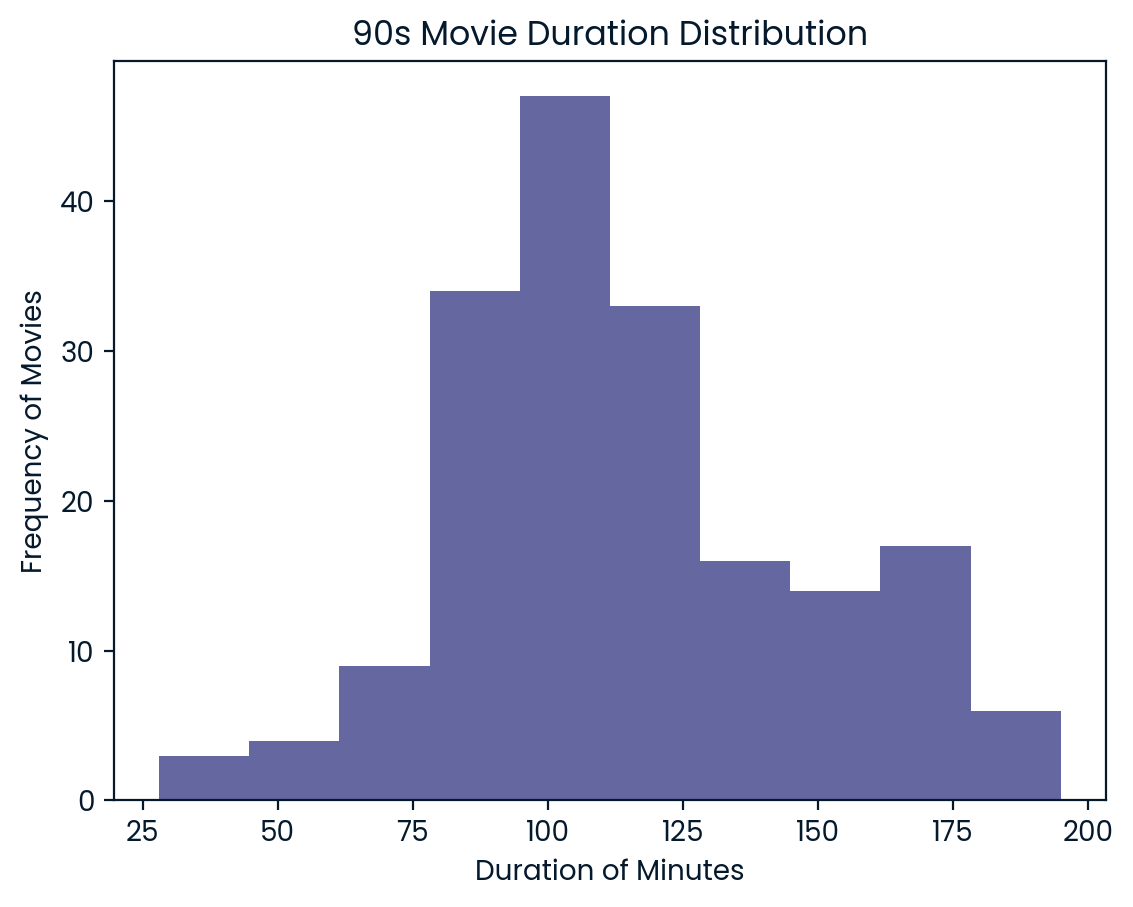

In [5]:
# Creating a histogram to check if the mode value corresponds to the histogram peak
# Default bin count is 10 
plt.hist(db_90s['duration'])
plt.title('90s Movie Duration Distribution')
plt.xlabel('Duration of Minutes')
plt.ylabel('Frequency of Movies')
plt.show()

In [6]:
# The mode value is 94 and the median value is 108 which correspond to the 75-125 range which have have two most frequent movie durations within their bins ---- Therefore an approximate answer could be....
duration = 94 


Task 2 - Short 90s action movies count

In [7]:
# Checking the unqiue values for the genres column 
unique_genres = netflix_df['genre'].unique()
print(unique_genres)

['Dramas' 'Horror Movies' 'Action' 'International TV' 'Documentaries'
 'Independent Movies' 'Comedies' 'Sci-Fi' 'International Movies'
 'Children' 'TV Shows' 'Uncategorized' 'Classic Movies' 'Thrillers'
 'Stand-Up' 'Anime Features' 'Music' 'Anime Series' 'Kids' 'Docuseries'
 'Crime TV' 'British TV' 'Cult Movies' 'TV Action' 'Romantic TV'
 'TV Horror' 'Romantic Movies' 'TV Comedies' 'Classic' 'Reality TV'
 'LGBTQ Movies']


In [8]:
# Subsetting the 90s dataframe for only 'Action' genre
action_movies_90s = db_90s[db_90s['genre'] == 'Action']


In [9]:
# Create a boolean series containing true/false values for a duration below 90 minutes, and sum the result 
short_movie_count = (action_movies_90s['duration'] < 90).sum()
print(short_movie_count)

7


In [10]:
# Double check with the suggested method using iterrows, for loop and an if statement
count = 0
for label, row in action_movies_90s.iterrows() :
    if row['duration'] < 90:
        count += 1
    else:
        count = count
print(count)

7
